# B04-KM — K-Means trên RFM (log1p(R,F,M) → MinMaxScaler → PCA 90%)

Thí nghiệm **B04-KM** (người chạy: Thuận, hạn nội bộ 17/11/2026) theo chiến lược model. So với B01, **thay StandardScaler bằng MinMaxScaler**. Quy trình: làm sạch → RFM → log1p(R,F,M) → MinMaxScaler → PCA 90% → K-Means.

## Params

In [ ]:
FEATURES = ["Recency", "Frequency", "Monetary"]
RANDOM_STATE = 42
N_INIT = 20                 
K_RANGE = range(2, 11)      

## Import thư viện và đọc dữ liệu

In [ ]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())


DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4,327 khách, dùng chung file feature của nhóm. Monetary lệch phải rất mạnh (trung vị 657.9, max 278,748) nên tiền xử lý ảnh hưởng nhiều đến kết quả.

## Tiền xử lý

log1p(R,F,M) → MinMaxScaler → PCA 90%.

In [3]:
prep = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", MinMaxScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)
ev = prep["pca"].explained_variance_ratio_
print("Phương sai từng PC:", ev.round(4), "| giữ lại:", round(ev.sum(), 4))
print("MinMax sau log1p: min =", prep["scaler"].transform(np.log1p(X.values)).min(axis=0).round(3), ", max =", prep["scaler"].transform(np.log1p(X.values)).max(axis=0).round(3))

Kích thước đầu vào mô hình: (4327, 2)
Phương sai từng PC: [0.7901 0.1796] | giữ lại: 0.9697
MinMax sau log1p: min = [0. 0. 0.] , max = [1. 1. 1.]


## Quét k = 2..10 và chọn theo Silhouette

Chọn k=2: Silhouette=0.4668, DBI=0.8084, CHI=5413.4, cụm nhỏ nhất=1873


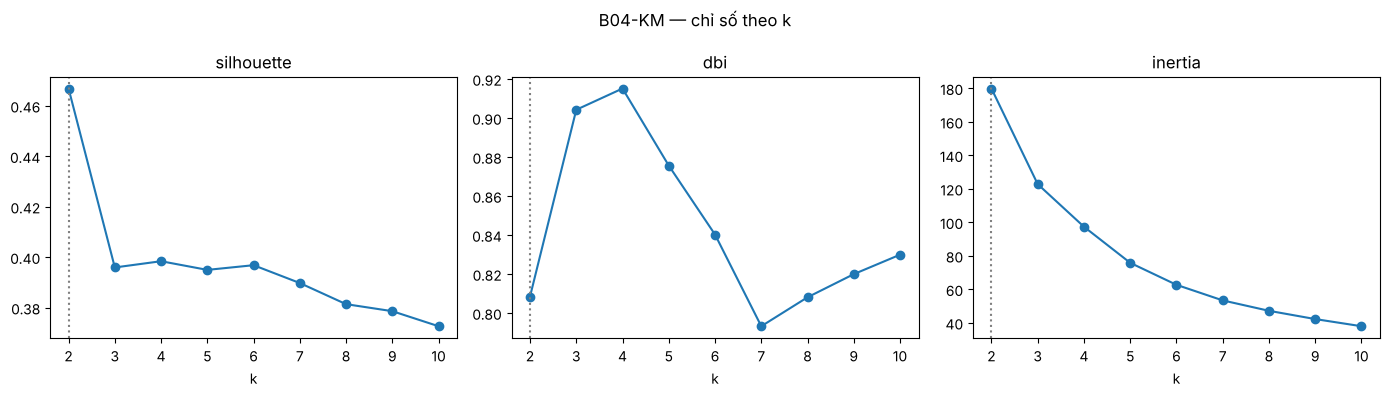

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.4668,0.8084,5413.4250,179.7919,1873
1,3,0.3959,0.9042,4971.1579,122.7044,1020
2,4,0.3984,0.9151,4555.4756,97.2840,793
3,5,0.3949,0.8756,4695.2665,75.7342,457
4,6,0.3968,0.8402,4724.0058,62.6078,356
5,7,0.3897,0.7932,4747.9831,53.3068,245
6,8,0.3814,0.8080,4686.9910,47.0941,195
7,9,0.3786,0.8199,4643.0976,42.1605,179
8,10,0.3726,0.8299,4645.6202,37.8875,146


In [4]:
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z)
    sizes = np.bincount(km.labels_, minlength=k)
    rows.append({"k": k, "silhouette": silhouette_score(Z, km.labels_), "dbi": davies_bouldin_score(Z, km.labels_),
                 "chi": calinski_harabasz_score(Z, km.labels_), "inertia": km.inertia_, "min_cluster": int(sizes.min())})
res = pd.DataFrame(rows)
best = res.loc[res["silhouette"].idxmax()]
print(f"Chọn k={int(best['k'])}: Silhouette={best['silhouette']:.4f}, DBI={best['dbi']:.4f}, CHI={best['chi']:.1f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "inertia"]):
    ax.plot(res["k"], res[col], marker="o"); ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col)
plt.suptitle("B04-KM — chỉ số theo k"); plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics_by_k.png", dpi=150); plt.show()
res.round(4)

**Nhận xét:** Silhouette cao nhất ở k=2 (0.4668); DBI 0.8084, CHI 5413.4. Cụm nhỏ nhất có 1873 khách (43.29%).

## Train mô hình cuối

In [5]:
K = int(best["k"])
model = Pipeline([("prep", Pipeline([
        ("log1p", FunctionTransformer(np.log1p, validate=True)),
        ("scaler", MinMaxScaler()),
        ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
    ])),
                  ("kmeans", KMeans(n_clusters=K, n_init=N_INIT, random_state=RANDOM_STATE))]).fit(X.values)
labels = model["kmeans"].labels_
assert np.allclose(model["prep"].transform(X.values), Z)
print("Số khách mỗi cụm:", dict(enumerate(np.bincount(labels).tolist())))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Số khách mỗi cụm: {0: 2454, 1: 1873}
Silhouette: 0.4668 | DBI: 0.8084


## Hồ sơ cụm (trên RFM gốc, trung vị)

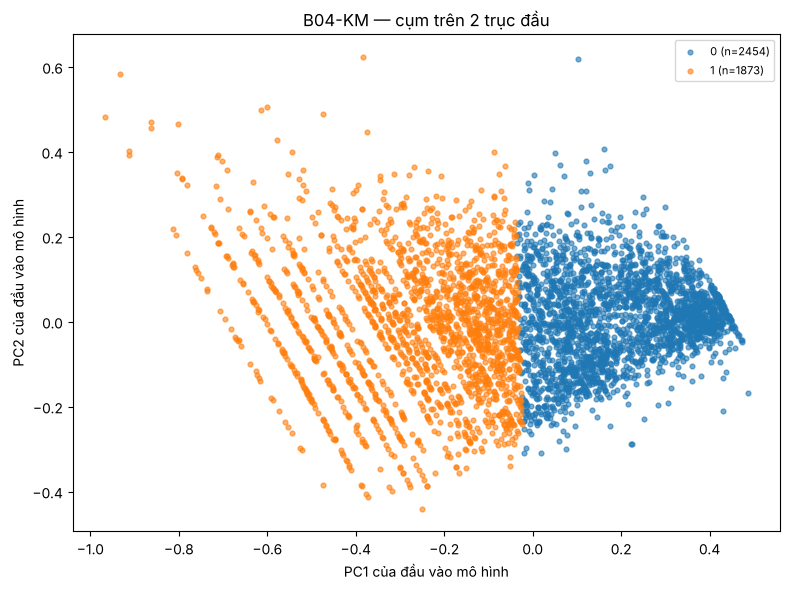

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,2454,120.0,1.0,383.8,56.7,19.4
1,1873,16.0,5.0,1488.7,43.3,80.6


In [6]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("B04-KM — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 1 có Monetary trung vị cao nhất (1,489), gồm 1873 khách (43.3%) nhưng chiếm 80.6% tổng Monetary. Cụm 0 đông nhất (56.7% khách, Recency trung vị 120 ngày).

## Đối chiếu với B01 (cùng tham số model)

In [ ]:

prep_parent = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Zp = prep_parent.fit_transform(X.values)
lp = KMeans(n_clusters=K, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(Zp)
ari_parent = adjusted_rand_score(labels, lp)
same_dims = Zp.shape[1] == Z.shape[1]
same_geometry = same_dims and np.allclose(np.linalg.norm(Z[:300, None] - Z[None, :300], axis=2),
                                          np.linalg.norm(Zp[:300, None] - Zp[None, :300], axis=2), atol=1e-8)
print(f"B04: {Z.shape[1]} chiều | B01: {Zp.shape[1]} chiều")
print(f"ARI giữa nhãn B04 và nhãn B01 (cùng tham số): {ari_parent:.4f}")
print("Cùng hình học khoảng cách:", same_geometry)

B04: 2 chiều | B01: 2 chiều
ARI giữa nhãn B04 và nhãn B01 (cùng tham số): 0.5157
Cùng hình học khoảng cách: False


**Nhận xét:** ARI giữa B04 và B01 (cùng tham số) = 0.5157; số chiều đầu vào 2 so với 2. Nhãn khác một phần: thay đổi tiền xử lý có tác động vừa phải.

## Lưu kết quả

In [9]:
res.to_csv(OUT / "kmeans_b04_metrics_by_k.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_b04_labels.csv", index=False)
joblib.dump(model, "kmeans_b04_model.pkl")
params = {"experiment": "B04-KM", "features": FEATURES, "transform": 'log1p',
          "scaler": "MinMaxScaler", "pca": 0.9,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "pca_variance_kept": float(model["prep"]["pca"].explained_variance_ratio_.sum()),
          "k": K, "silhouette": float(silhouette_score(Z, labels)), "dbi": float(davies_bouldin_score(Z, labels)),
          "chi": float(calinski_harabasz_score(Z, labels)), "inertia": float(model["kmeans"].inertia_),
          "n_init": N_INIT,
          "ari_vs_parent_fixed_params": {"parent": "B01", "ari": float(ari_parent)}}
json.dump(params, open(OUT / "kmeans_b04_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['kmeans_b04_labels.csv', 'kmeans_b04_metrics_by_k.csv', 'kmeans_b04_params.json']


**Kết luận B04-KM:** K-Means chọn k=2 (Silhouette 0.4668) trên 2 chiều đầu vào. ARI với B01 (cùng tham số) = 0.5157. Silhouette giữa các cấu hình khác không gian đầu vào (số chiều, scaler) không so sánh trực tiếp được; dùng ARI và hồ sơ cụm trên RFM gốc để so sánh.